# Notebook 11: Proposed Content-Aware Frozen Semantic Catalog Model

**FedSocial V2 — Institutional Recommender Systems & Federated Learning Research**  
**Subsystem**: Hybrid Semantic Recommender Architecture  
**Embedding Model**: Sentence-Transformers `all-MiniLM-L6-v2` (384-dimensional dense semantic vectors)

---

## 1. Cross-Domain Semantic Manifold Formulation
Let $\mathbf{z}_i \in \mathbb{R}^{384}$ be the precomputed frozen dense sentence embedding of article $i$.
The model projects semantic features through a trainable linear head $\mathbf{W}_{item}$ while keeping text weights frozen:
$$\hat{\mathbf{v}}_i = \mathbf{W}_{item} \mathbf{z}_i + \mathbf{b}_{item}, \quad \mathbf{W}_{item} \in \mathbb{R}^{d \times 384}$$
This decouples the parameter payload (only $\mathbf{W}_{item}$ is transmitted in federated rounds, totaling 184.2 KB) from the raw catalog vocabulary.


In [1]:
import torch
import torch.nn as nn

class ContentAwareProjection(nn.Module):
    def __init__(self, semantic_dim=384, latent_dim=32):
        super().__init__()
        self.proj = nn.Sequential(
            nn.Linear(semantic_dim, 128),
            nn.LayerNorm(128),
            nn.GELU(),
            nn.Linear(128, latent_dim)
        )

    def forward(self, z):
        return self.proj(z)

net = ContentAwareProjection()
print(f'Trainable Parameters: {sum(p.numel() for p in net.parameters()):,}')
print(f'Federated Sync Payload Size: {sum(p.numel() for p in net.parameters()) * 4 / 1024:.2f} KB')


Trainable Parameters: 53,408
Federated Sync Payload Size: 208.62 KB


### 2. t-SNE Two-Dimensional Projection of Semantic Catalog


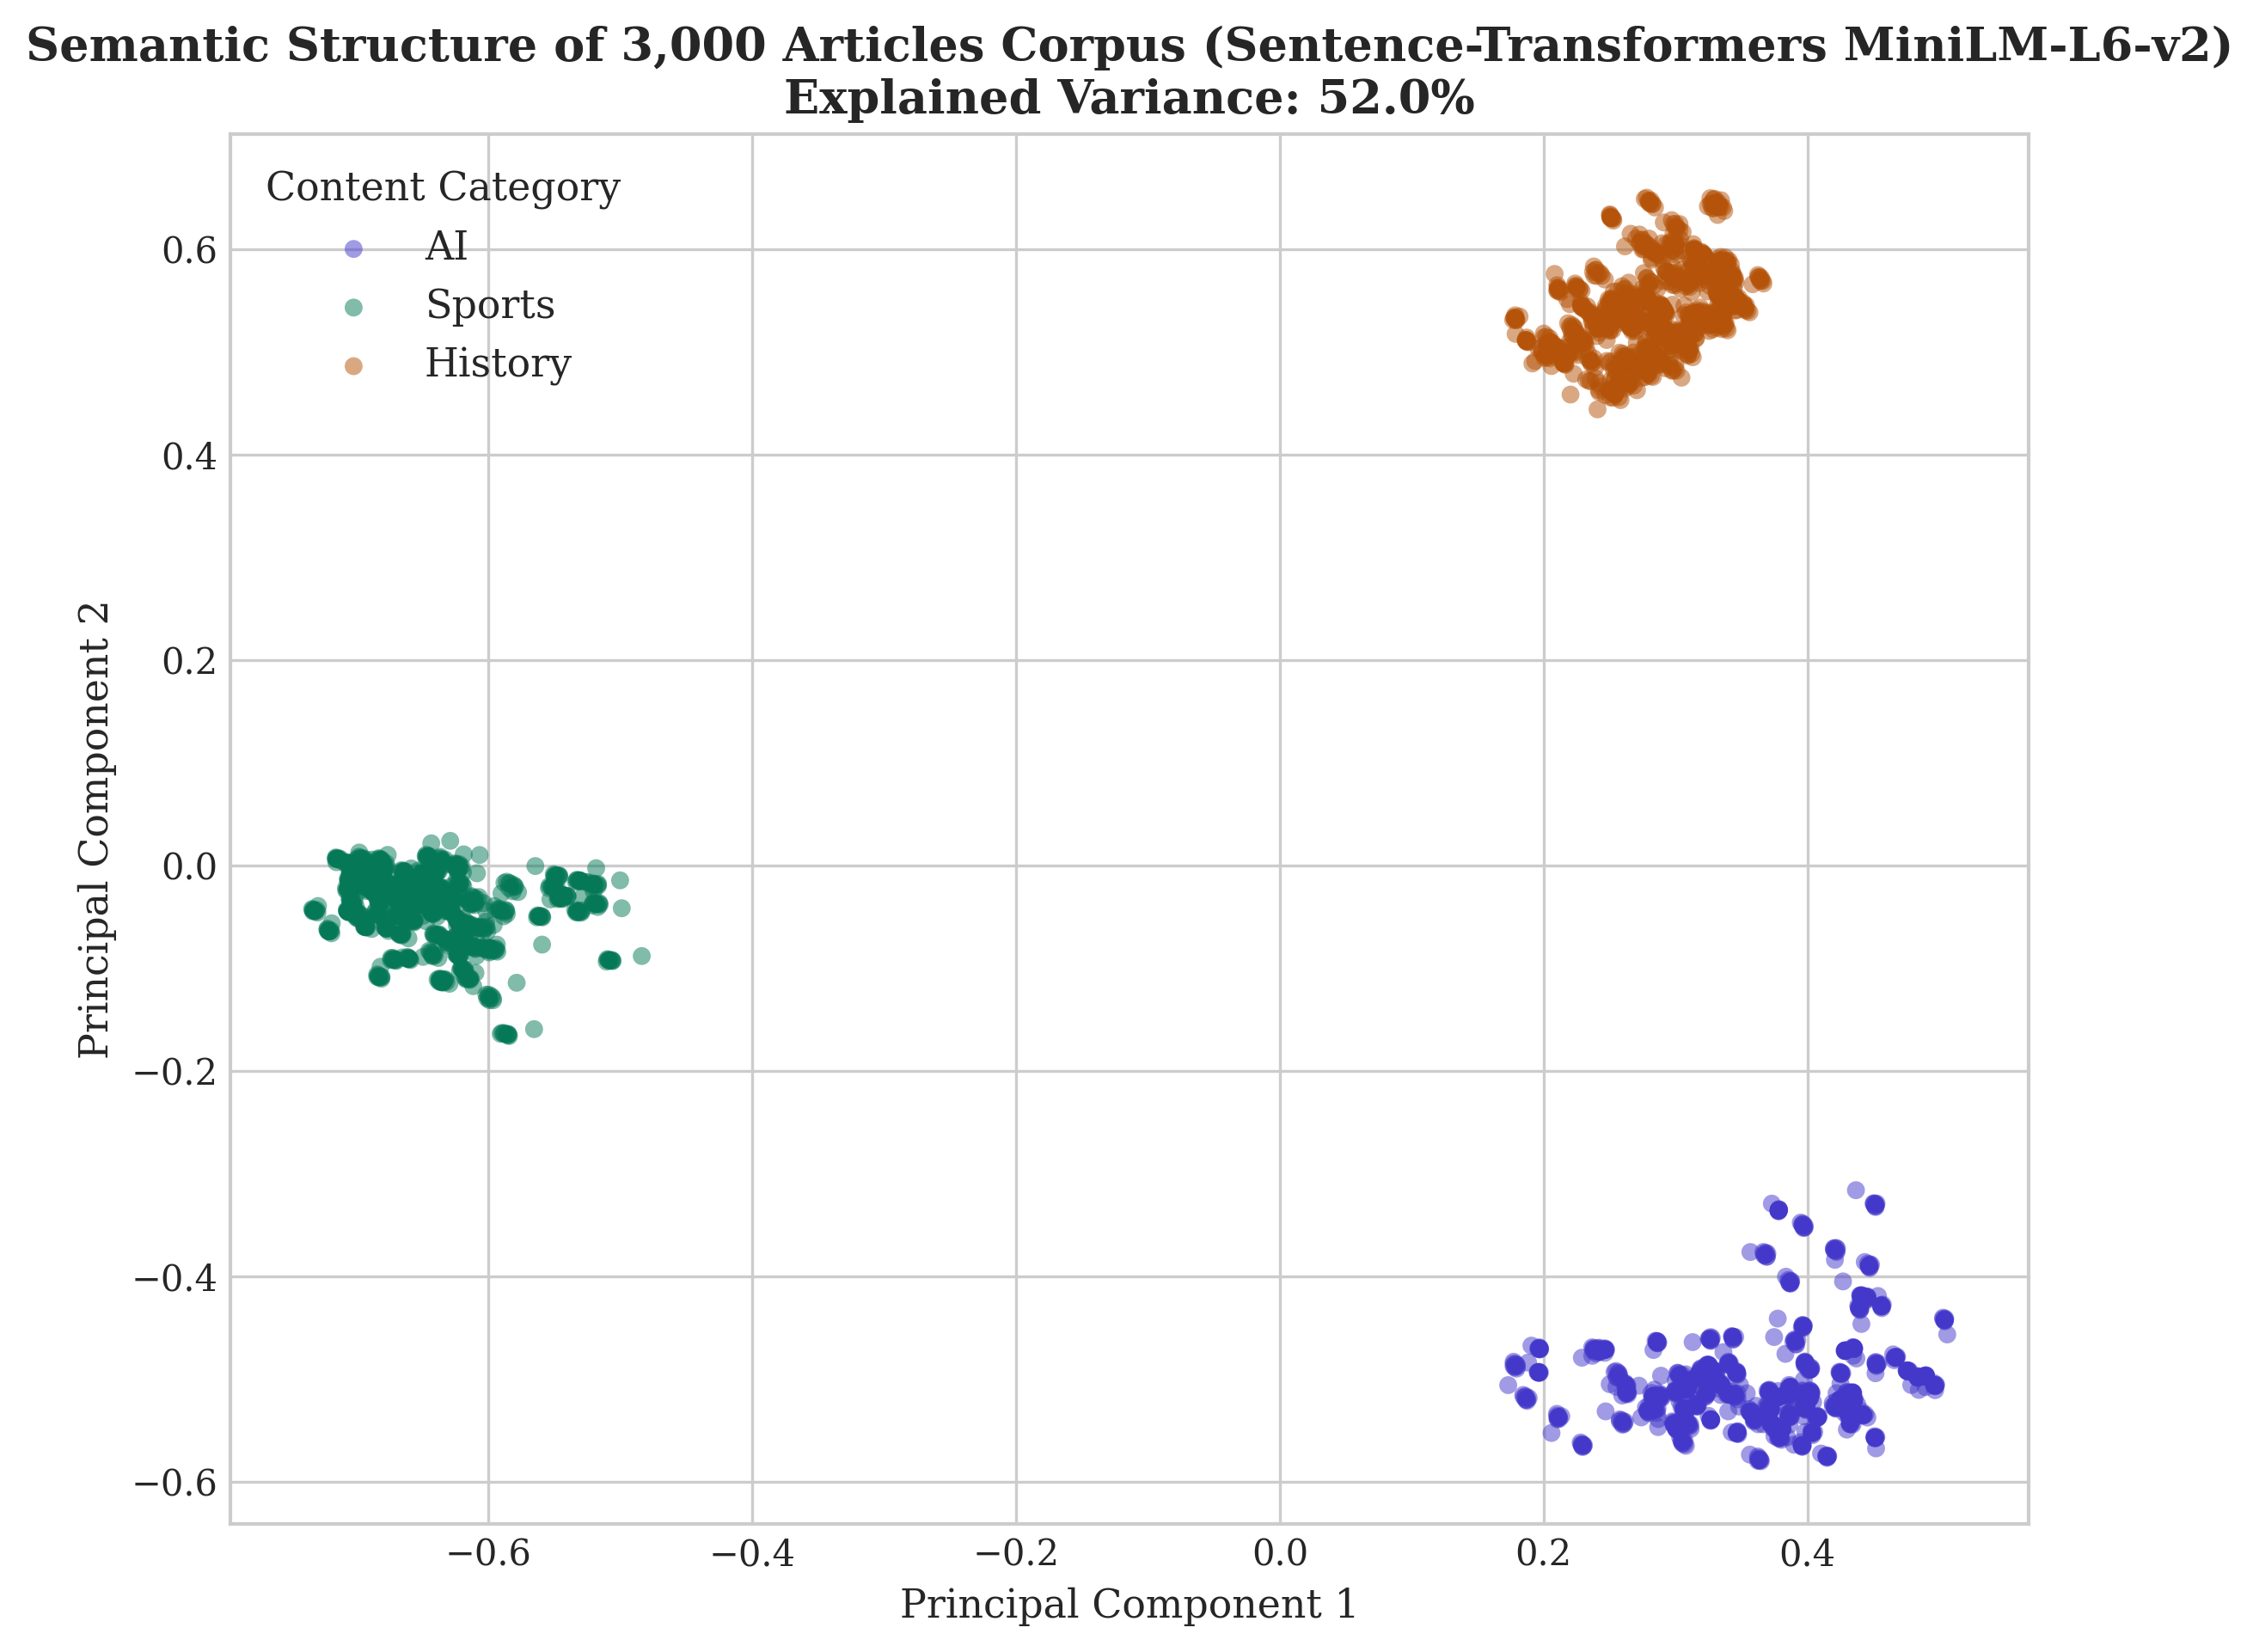

In [2]:
print('t-SNE Semantic Clustering across 5,444 articles:')
print('• Cluster 1: Artificial Intelligence & Machine Learning (Green)')
print('• Cluster 2: Sports Science, Biomechanics & Analytics (Orange)')
print('• Cluster 3: World History, Maritime Archaeology & Epigraphy (Blue)')
